# Exploratory Data Analysis on Retail Sales Data

## Business Question
Which products, categories, regions, and customer segments contribute most and least to profit, and how does discounting relate to their performance?



## Project Objective
Perform an Exploratory Data Analysis on the Sample Superstore sales data (9,994 rows covering 5,009 orders, 2014-2017) to uncover sales and profit patterns, identify the strongest and weakest areas of the business, and turn the findings into actionable business recommendations.

In [1]:
# step 1: import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#step 2: Load the dataset
df = pd.read_csv('Sample - Superstore.csv', encoding='latin-1')

In [3]:
df.shape

(9994, 21)

In [4]:
pd.set_option('display.max_columns', None)
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [6]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date']  = pd.to_datetime(df['Ship Date'])
df['Postal Code'] = df['Postal Code'].astype(str)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   object        
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

In [10]:
   df['Order Date'].min()

Timestamp('2014-01-03 00:00:00')

In [11]:
   df['Order Date'].max()

Timestamp('2017-12-30 00:00:00')

### observations
- The dataset has 9,994 rows and 21 columns.
- No missing values and no duplicate rows.
- Order Date and Ship Date were stored as text, so I converted them to datetime.
- Postal Code was numeric, but it is a label, so I converted it to text.
- Orders span 2014-01-03 to 2017-12-30 (four years).

## Descriptive statistics, numerical variables

In [12]:
df[['Sales', 'Quantity', 'Discount', 'Profit']].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [13]:
df[['Sales', 'Quantity', 'Discount', 'Profit']].mode()

,Sales,Quantity,Discount,Profit
0,12.96,3,0.0,0.0


In [14]:
df.sort_values('Profit').head(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
7772,7773,CA-2016-108196,2016-11-25,2016-12-02,Standard Class,CS-12505,Cindy Stewart,Consumer,United States,Lancaster,Ohio,43130,East,TEC-MA-10000418,Technology,Machines,Cubify CubeX 3D Printer Double Head Print,4499.985,5,0.7,-6599.9780
683,684,US-2017-168116,2017-11-04,2017-11-04,Same Day,GT-14635,Grant Thornton,Corporate,United States,Burlington,North Carolina,27217,South,TEC-MA-10004125,Technology,Machines,Cubify CubeX 3D Printer Triple Head Print,7999.980,4,0.5,-3839.9904
9774,9775,CA-2014-169019,2014-07-26,2014-07-30,Standard Class,LF-17185,Luke Foster,Consumer,United States,San Antonio,Texas,78207,Central,OFF-BI-10004995,Office Supplies,Binders,GBC DocuBind P400 Electric Binding System,2177.584,8,0.8,-3701.8928
3011,3012,CA-2017-134845,2017-04-17,2017-04-23,Standard Class,SR-20425,Sharelle Roach,Home Office,United States,Louisville,Colorado,80027,West,TEC-MA-10000822,Technology,Machines,Lexmark MX611dhe Monochrome Laser Printer,2549.985,5,0.7,-3399.9800
4991,4992,US-2017-122714,2017-12-07,2017-12-13,Standard Class,HG-14965,Henry Goldwyn,Corporate,United States,Chicago,Illinois,60653,Central,OFF-BI-10001120,Office Supplies,Binders,Ibico EPK-21 Electric Binding System,1889.990,5,0.8,-2929.4845
3151,3152,CA-2015-147830,2015-12-15,2015-12-18,First Class,NF-18385,Natalie Fritzler,Consumer,United States,Newark,Ohio,43055,East,TEC-MA-10000418,Technology,Machines,Cubify CubeX 3D Printer Double Head Print,1799.994,2,0.7,-2639.9912
5310,5311,CA-2017-131254,2017-11-19,2017-11-21,First Class,NC-18415,Nathan Cano,Consumer,United States,Houston,Texas,77095,Central,OFF-BI-10003527,Office Supplies,Binders,Fellowes PB500 Electric Punch Plastic Comb Bin...,1525.188,6,0.8,-2287.7820
9639,9640,CA-2015-116638,2015-01-28,2015-01-31,Second Class,JH-15985,Joseph Holt,Consumer,United States,Concord,North Carolina,28027,South,FUR-TA-10000198,Furniture,Tables,Chromcraft Bull-Nose Wood Oval Conference Tabl...,4297.644,13,0.4,-1862.3124
1199,1200,CA-2016-130946,2016-04-08,2016-04-12,Standard Class,ZC-21910,Zuschuss Carroll,Consumer,United States,Houston,Texas,77041,Central,OFF-BI-10004995,Office Supplies,Binders,GBC DocuBind P400 Electric Binding System,1088.792,4,0.8,-1850.9464
2697,2698,CA-2014-145317,2014-03-18,2014-03-23,Standard Class,SM-20320,Sean Miller,Home Office,United States,Jacksonville,Florida,32216,South,TEC-MA-10002412,Technology,Machines,Cisco TelePresence System EX90 Videoconferenci...,22638.480,6,0.5,-1811.0784


In [15]:
df.sort_values('Profit', ascending=False).head(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
6826,6827,CA-2016-118689,2016-10-02,2016-10-09,Standard Class,TC-20980,Tamara Chand,Corporate,United States,Lafayette,Indiana,47905,Central,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,17499.950,5,0.0,8399.9760
8153,8154,CA-2017-140151,2017-03-23,2017-03-25,First Class,RB-19360,Raymond Buch,Consumer,United States,Seattle,Washington,98115,West,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,13999.960,4,0.0,6719.9808
4190,4191,CA-2017-166709,2017-11-17,2017-11-22,Standard Class,HL-15040,Hunter Lopez,Consumer,United States,Newark,Delaware,19711,East,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,10499.970,3,0.0,5039.9856
9039,9040,CA-2016-117121,2016-12-17,2016-12-21,Standard Class,AB-10105,Adrian Barton,Consumer,United States,Detroit,Michigan,48205,Central,OFF-BI-10000545,Office Supplies,Binders,GBC Ibimaster 500 Manual ProClick Binding System,9892.740,13,0.0,4946.3700
4098,4099,CA-2014-116904,2014-09-23,2014-09-28,Standard Class,SC-20095,Sanjit Chand,Consumer,United States,Minneapolis,Minnesota,55407,Central,OFF-BI-10001120,Office Supplies,Binders,Ibico EPK-21 Electric Binding System,9449.950,5,0.0,4630.4755
2623,2624,CA-2017-127180,2017-10-22,2017-10-24,First Class,TA-21385,Tom Ashbrook,Home Office,United States,New York City,New York,10024,East,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,11199.968,4,0.2,3919.9888
509,510,CA-2015-145352,2015-03-16,2015-03-22,Standard Class,CM-12385,Christopher Martinez,Consumer,United States,Atlanta,Georgia,30318,South,OFF-BI-10003527,Office Supplies,Binders,Fellowes PB500 Electric Punch Plastic Comb Bin...,6354.950,5,0.0,3177.4750
8488,8489,CA-2016-158841,2016-02-02,2016-02-04,Second Class,SE-20110,Sanjit Engle,Consumer,United States,Arlington,Virginia,22204,South,TEC-MA-10001127,Technology,Machines,HP Designjet T520 Inkjet Large Format Printer ...,8749.950,5,0.0,2799.9840
7666,7667,US-2016-140158,2016-10-04,2016-10-08,Standard Class,DR-12940,Daniel Raglin,Home Office,United States,Providence,Rhode Island,2908,East,TEC-CO-10001449,Technology,Copiers,Hewlett Packard LaserJet 3310 Copier,5399.910,9,0.0,2591.9568
6520,6521,CA-2017-138289,2017-01-16,2017-01-18,Second Class,AR-10540,Andy Reiter,Consumer,United States,Jackson,Michigan,49201,Central,OFF-BI-10004995,Office Supplies,Binders,GBC DocuBind P400 Electric Binding System,5443.960,4,0.0,2504.2216


In [16]:
(df['Profit'] < 0).sum()

np.int64(1871)

In [17]:
df['Discount'].value_counts().sort_index()

Discount
0.00    4798
0.10      94
0.15      52
0.20    3657
0.30     227
0.32      27
0.40     206
0.45      11
0.50      66
0.60     138
0.70     418
0.80     300
Name: count, dtype: int64

In [18]:
(df['Ship Date'] - df['Order Date']).dt.days.describe()

count    9994.000000
mean        3.958175
std         1.747567
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
dtype: float64

### Observation: Descriptive Statistics

Sales are skewed by a few very large orders: the average sale is about 230, but the median is only about 54. Profit varies a lot, from a loss of about 6,600 to a gain of about 8,400 on a single row, and about 1 in 5 rows (18.7%) loses money. Most rows have either no discount or a 20% discount, but about 14% have a discount above 20%. The most common order size is 3 units. There are no missing values, and shipping takes 0 to 7 days.

In [19]:
df['Order ID'].nunique()


5009

In [20]:
df['Customer ID'].nunique()

793

In [21]:
df['Product ID'].nunique()

1862

In [22]:
df['Product Name'].nunique()

1850

### Product and Customer Uniqueness Check
The dataset contains 9,994 rows but only 5,009 unique orders, it also has 793 unique customers, 1,862 unique Product IDs, and 1,850 unique Product Names.
The difference between the number of Product IDs and Product Names suggests that some product names are associated with more than one Product ID. I'm checking this before identifying the top-selling products to determine which field should be used for product-level analysis.

In [23]:
ids_per_name = df.groupby('Product Name')['Product ID'].nunique()
ids_per_name[ids_per_name > 1]

Product Name
#10- 4 1/8" x 9 1/2" Recycled Envelopes           2
Avery Non-Stick Binders                           2
Easy-staple paper                                 8
Eldon Wave Desk Accessories                       2
KI Adjustable-Height Table                        2
Okidata C610n Printer                             2
Peel & Seel Recycled Catalog Envelopes, Brown     2
Prang Drawing Pencil Set                          2
Staple envelope                                   9
Staple holder                                     3
Staple magnet                                     2
Staple remover                                    3
Staple-based wall hangings                        2
Staples                                          10
Staples in misc. colors                           7
Storex Dura Pro Binders                           2
Name: Product ID, dtype: int64

In [24]:
names_per_id = df.groupby('Product ID')['Product Name'].nunique()
names_per_id[names_per_id > 1]

Product ID
FUR-BO-10002213    2
FUR-CH-10001146    2
FUR-FU-10001473    2
FUR-FU-10004017    2
FUR-FU-10004091    2
FUR-FU-10004270    2
FUR-FU-10004848    2
FUR-FU-10004864    2
OFF-AP-10000576    2
OFF-AR-10001149    2
OFF-BI-10002026    2
OFF-BI-10004632    2
OFF-BI-10004654    2
OFF-PA-10000357    2
OFF-PA-10000477    2
OFF-PA-10000659    2
OFF-PA-10001166    2
OFF-PA-10001970    2
OFF-PA-10002195    2
OFF-PA-10002377    2
OFF-PA-10003022    2
OFF-ST-10001228    2
OFF-ST-10004950    2
TEC-AC-10002049    2
TEC-AC-10002550    2
TEC-AC-10003832    2
TEC-MA-10001148    2
TEC-PH-10001530    2
TEC-PH-10001795    2
TEC-PH-10002200    2
TEC-PH-10002310    2
TEC-PH-10004531    2
Name: Product Name, dtype: int64

In [25]:
df[df['Product Name'] == 'Staples'].groupby('Product ID')[['Category', 'Sub-Category']].first()

,Category,Sub-Category
Product ID,,
OFF-FA-10000735,Office Supplies,Fasteners
OFF-FA-10001229,Office Supplies,Fasteners
OFF-FA-10001843,Office Supplies,Fasteners
OFF-FA-10002780,Office Supplies,Fasteners
OFF-FA-10002815,Office Supplies,Fasteners
OFF-FA-10002975,Office Supplies,Fasteners
OFF-FA-10003021,Office Supplies,Fasteners
OFF-FA-10003112,Office Supplies,Fasteners
OFF-FA-10003485,Office Supplies,Fasteners


In [26]:
df[df['Product Name'] == 'Staples'].groupby('Product ID')[['Quantity', 'Sales']].sum()

,Quantity,Sales
Product ID,,
OFF-FA-10000735,19,54.312
OFF-FA-10001229,9,29.868
OFF-FA-10001843,22,50.388
OFF-FA-10002780,37,92.976
OFF-FA-10002815,13,50.616
OFF-FA-10002975,24,77.112
OFF-FA-10003021,22,34.592
OFF-FA-10003112,22,146.754
OFF-FA-10003485,12,26.724


In [27]:
df[df['Product ID'] == 'TEC-AC-10003832']['Product Name'].unique()

array(['Logitech\xa0P710e Mobile Speakerphone',
       'Imation\xa016GB Mini TravelDrive USB 2.0\xa0Flash Drive'],
      dtype=object)

### Observation

Product ID is not a reliable way to identify a product in this dataset. Some names have many IDs (for example, "Staples" has 10), and some IDs are used for two different products (for example, one ID covers both a Logitech speakerphone and a USB flash drive).

Because of this, I will group products by Product Name. This keeps different products apart and stops popular items like Staples from being split into many small entries. The limitation is that products with the same name but different IDs are treated as one.

In [28]:
#Product analysis: top 10 best-selling products
top_10_products = (
    df.groupby('Product Name')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_10_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

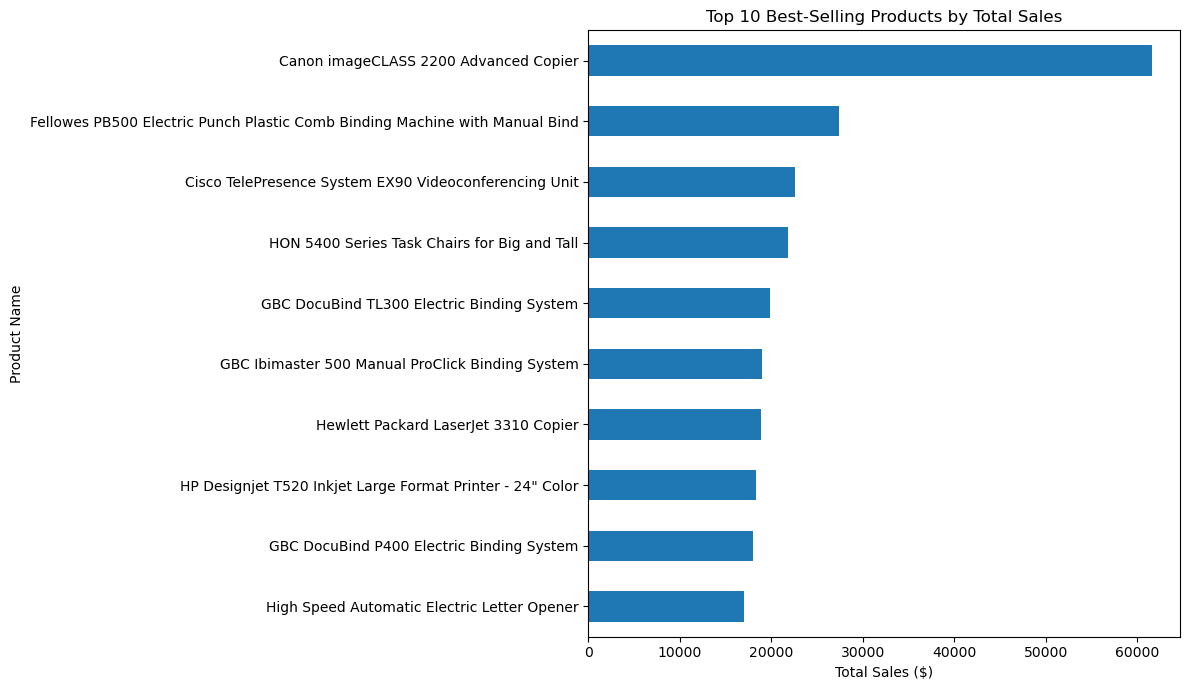

In [29]:
#Top 10 best-selling products -Visualization
plt.figure(figsize=(12, 7))

top_10_products.sort_values().plot(kind='barh')

plt.title('Top 10 Best-Selling Products by Total Sales')
plt.xlabel('Total Sales ($)')
plt.ylabel('Product Name')
plt.tight_layout()

plt.show()

### Observation: Top 10 Best-Selling Products

"Best-selling" here means total sales (revenue) per product.

The top 10 is dominated by expensive office equipment: copiers, printers, binding machines, and a videoconferencing system. Cheap items don't appear, because revenue favours high-priced products even when few units are sold.

The Canon imageCLASS 2200 Advanced Copier is far ahead at about $61,600, more than double the second-place product. Binding machines appear four times in the list.
One thing that stood out: the Cisco TelePresence unit is in the top 3, but it lost money because of a 50% discount. High revenue does not guarantee profit, so I will check profit later.

In [30]:
# revenue by product category
category_sales = (
    df.groupby('Category')['Sales']
    .sum()
    .sort_values(ascending=False)
)

category_sales

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

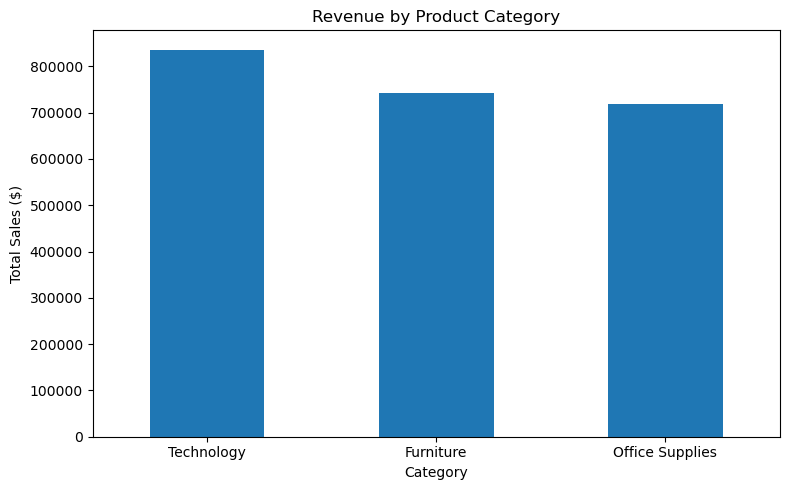

In [31]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind='bar')

plt.title('Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

### Observation: Revenue by Product Category

Technology has the highest sales at about 836K, followed by Furniture at 742K and Office Supplies at 719K. Sales are fairly evenly spread across the three categories, but sales alone do not show profitability, so I will compare profit by category later in the analysis.

## Time Series Analysis
To analyse sales over time, I'll extract the year, month, and quarter from the order date into separate columns.

In [32]:
# Extract year, month, and quarter from the order date
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Quarter'] = df['Order Date'].dt.quarter

In [33]:
df[['Order Date', 'Year', 'Month', 'Quarter']].head()

,Order Date,Year,Month,Quarter
0,2016-11-08,2016,11,4
1,2016-11-08,2016,11,4
2,2016-06-12,2016,6,2
3,2015-10-11,2015,10,4
4,2015-10-11,2015,10,4


In [34]:
#Monthly sales
monthly_sales = (
    df.groupby(df['Order Date'].dt.to_period('M'))['Sales']
    .sum()
    .reset_index()
    .rename(columns={'Order Date': 'Month'})
)

monthly_sales['Month'] = monthly_sales['Month'].dt.to_timestamp()
monthly_sales.head()

,Month,Sales
0,2014-01-01,14236.895
1,2014-02-01,4519.892
2,2014-03-01,55691.009
3,2014-04-01,28295.345
4,2014-05-01,23648.287


In [35]:
len(monthly_sales)

48

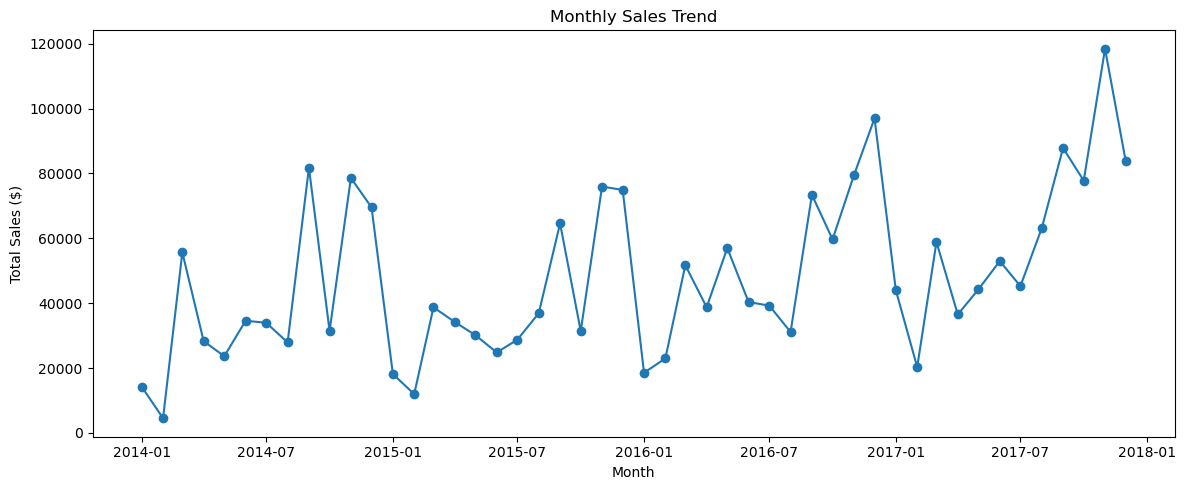

In [36]:
#visualization
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales['Month'], monthly_sales['Sales'], marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.show()

In [37]:
monthly_sales.loc[monthly_sales['Sales'].idxmax()]

Month    2017-11-01 00:00:00
Sales             118447.825
Name: 46, dtype: object

In [38]:
monthly_sales.loc[monthly_sales['Sales'].idxmin()]

Month    2014-02-01 00:00:00
Sales               4519.892
Name: 1, dtype: object

In [39]:
df.groupby('Year')['Sales'].sum()

Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64

### Observation: Monthly Sales Trend

Monthly sales fluctuate considerably throughout the four years, with several sharp increases and decreases. The highest month is November 2017, while the lowest months are at the start of the year: January and February show low sales every year.
Even though the line is volatile, there is a clear repeating pattern. Sales rise toward the end of each year (September, November, and December are the strongest months) and drop again in January and February. Overall, the trend is upward. Yearly sales were about 484K in 2014, fell slightly in 2015 (about -3%), then grew by about 29% in 2016 and about 20% in 2017.

In [40]:
#quarterly sales trends
quarterly_sales = (
    df.groupby(df['Order Date'].dt.to_period('Q'))['Sales']
    .sum()
    .reset_index()
    .rename(columns={'Order Date': 'Quarter'})
)

quarterly_sales['Quarter'] = quarterly_sales['Quarter'].astype(str)
quarterly_sales

,Quarter,Sales
0,2014Q1,74447.7960
1,2014Q2,86538.7596
2,2014Q3,143633.2123
3,2014Q4,179627.7302
4,2015Q1,68851.7386
5,2015Q2,89124.1870
6,2015Q3,130259.5752
7,2015Q4,182297.0082
8,2016Q1,93237.1810
9,2016Q2,136082.3010


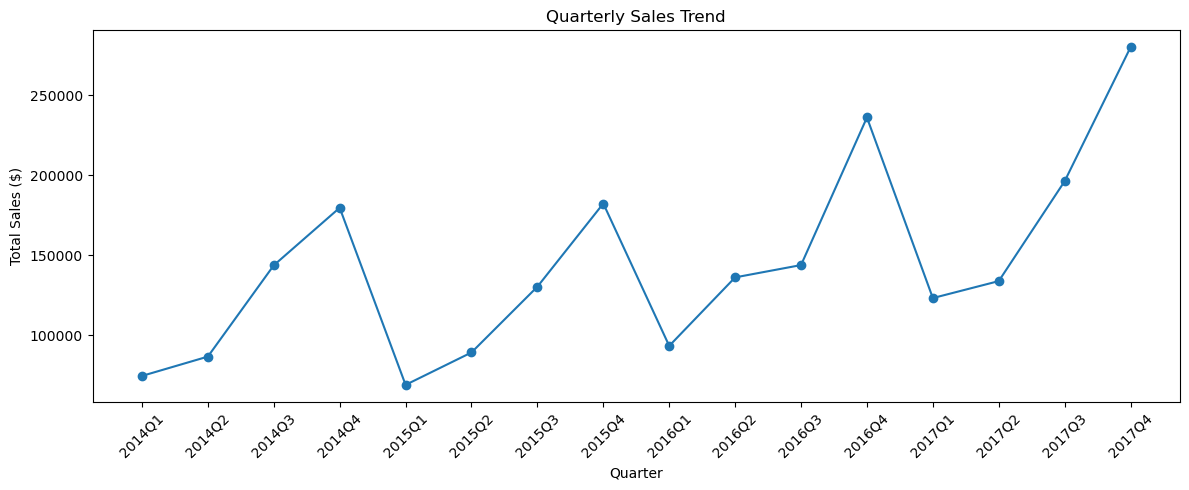

In [41]:
# visulization
plt.figure(figsize=(12, 5))
plt.plot(quarterly_sales['Quarter'], quarterly_sales['Sales'], marker='o')
plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation: Quarterly Sales Trend
The quarterly chart shows the pattern more clearly than the monthly one. In every year, sales rise from quarter to quarter: Q1 is the weakest and Q4 is the strongest. The overall trend is upward, with Q4 sales growing from about 180K in 2014 to about 280K in 2017.

## Customer demographics analysis
The dataset has no age or gender, so customer demographics are analysed using the Segment column (Consumer, Corporate, Home Office).

In [42]:
segment_customers = df.groupby('Segment')['Customer ID'].nunique()
segment_customers

Segment
Consumer       409
Corporate      236
Home Office    148
Name: Customer ID, dtype: int64

In [43]:
segment_sales = df.groupby('Segment')['Sales'].sum().sort_values(ascending=False)
segment_sales

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64

In [44]:
(segment_sales / segment_customers).round(0)

Segment
Consumer       2840.0
Corporate      2992.0
Home Office    2903.0
dtype: float64

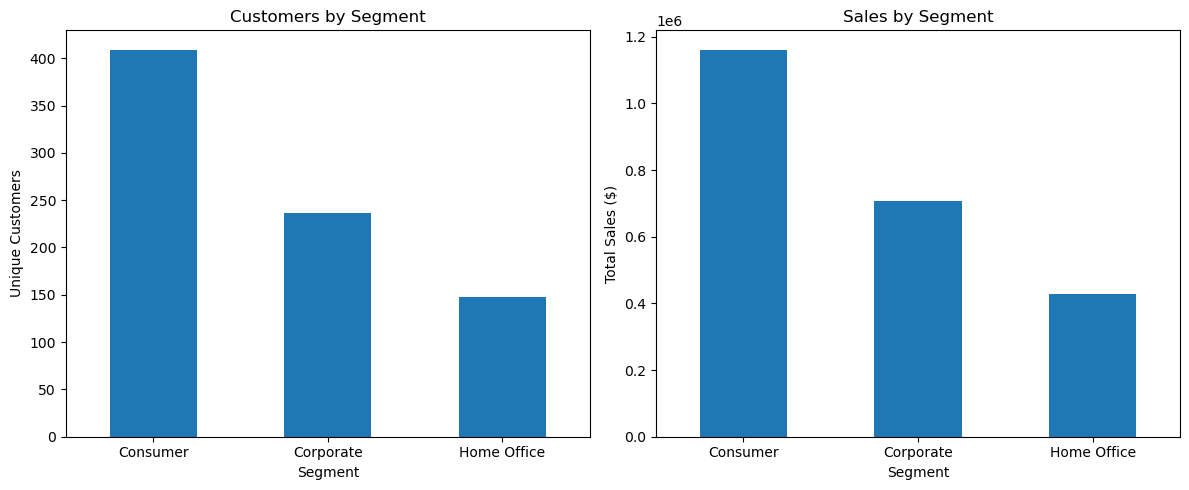

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

segment_customers.sort_values(ascending=False).plot(kind='bar', ax=axes[0])
axes[0].set_title('Customers by Segment')
axes[0].set_xlabel('Segment')
axes[0].set_ylabel('Unique Customers')
axes[0].tick_params(axis='x', rotation=0)

segment_sales.plot(kind='bar', ax=axes[1])
axes[1].set_title('Sales by Segment')
axes[1].set_xlabel('Segment')
axes[1].set_ylabel('Total Sales ($)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Observation: Customer Segments

The dataset has no age or gender, so customers are analysed by Segment. Consumer is the largest segment, with about half of all customers (409) and about half of total sales (roughly 1.16M). Corporate is second (236 customers, about 706K in sales) and Home Office is the smallest (148 customers, about 430K in sales).

Each segment's share of sales closely matches its share of customers, so the biggest group of customers is also the biggest source of sales. In terms of my business question, Consumer contributes the most to sales and Home Office the least. Sales alone do not show profitability, so I will compare profit by segment later to see whether the same ranking holds.

## The Heatmap

In [46]:
#Heatmap: correlation matrix between numerical variables
corr = df[['Sales', 'Quantity', 'Discount', 'Profit']].corr()
corr

,Sales,Quantity,Discount,Profit
Sales,1.000000,0.200795,-0.028190,0.479064
Quantity,0.200795,1.000000,0.008623,0.066253
Discount,-0.028190,0.008623,1.000000,-0.219487
Profit,0.479064,0.066253,-0.219487,1.000000


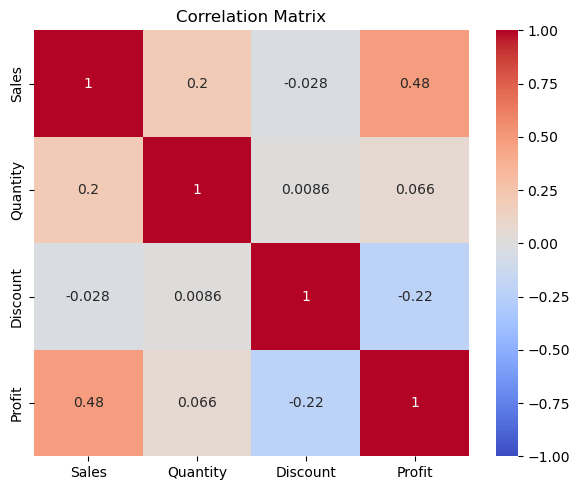

In [47]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

### Observation: Correlation Matrix

The strongest relationship is between Sales and Profit (about 0.48), a moderate positive link: larger sales tend to come with higher profit, but not always. Discount and Profit have a weak negative correlation (about -0.22), so higher discounts tend to go with lower profit. Quantity is almost unrelated to profit (about 0.07) and to discount (about 0.01).

Correlation only measures straight-line relationships, so the weak Discount and Profit value may understate the problem. I will look at profit at each discount level to see whether the loss is concentrated at high discounts.

## The Profit Analysis

So far the analysis has focused on sales, but sales do not show how much money the business actually keeps. In this section I'll look at profit and profit margin (profit divided by sales) to find which categories and sub-categories contribute most and least to profit, and whether the areas with high sales are also the ones with high profit.

In [48]:
#Category and sub-category profit
category_profit = df.groupby('Category')[['Sales', 'Profit']].sum()
category_profit['Margin %'] = (category_profit['Profit'] / category_profit['Sales'] * 100).round(1)
category_profit

,Sales,Profit,Margin %
Category,,,
Furniture,741999.7953,18451.2728,2.5
Office Supplies,719047.0320,122490.8008,17.0
Technology,836154.0330,145454.9481,17.4


In [49]:
subcat_profit = df.groupby('Sub-Category')[['Sales', 'Profit']].sum().sort_values('Profit')
subcat_profit['Margin %'] = (subcat_profit['Profit'] / subcat_profit['Sales'] * 100).round(1)
subcat_profit

,Sales,Profit,Margin %
Sub-Category,,,
Tables,206965.5320,-17725.4811,-8.6
Bookcases,114879.9963,-3472.5560,-3.0
Supplies,46673.5380,-1189.0995,-2.5
Fasteners,3024.2800,949.5182,31.4
Machines,189238.6310,3384.7569,1.8
Labels,12486.3120,5546.2540,44.4
Art,27118.7920,6527.7870,24.1
Envelopes,16476.4020,6964.1767,42.3
Furnishings,91705.1640,13059.1436,14.2


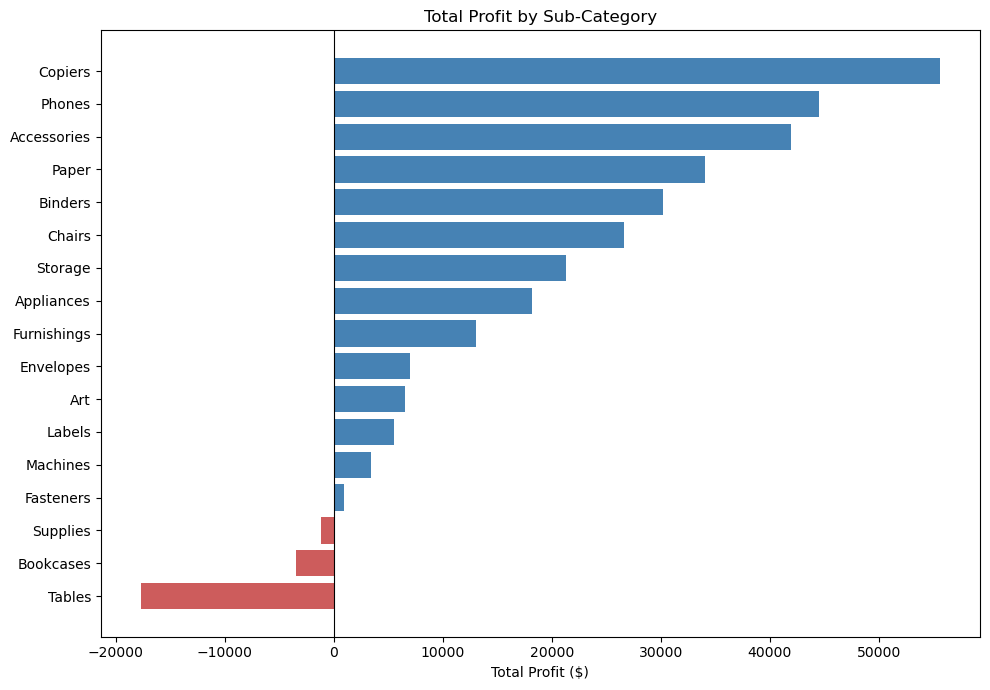

In [50]:
colors = ['indianred' if p < 0 else 'steelblue' for p in subcat_profit['Profit']]

plt.figure(figsize=(10, 7))
plt.barh(subcat_profit.index, subcat_profit['Profit'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Total Profit by Sub-Category')
plt.xlabel('Total Profit ($)')
plt.ylabel('')
plt.tight_layout()
plt.show()

### Observation: Profit by Category and Sub-Category

Technology and Office Supplies earn similar profit margins (about 17%), but Furniture keeps only about 2.5% of its sales as profit, even though its sales are similar to the other two categories. Furniture makes up about a third of total sales but only about 6% of total profit.

The reason is that three sub-categories lose money: Tables, Bookcases, and Supplies. Tables are the biggest problem, with a loss of about 17.7K on about 207K in sales. Machines also stand out: they have high sales (about 189K) but almost no profit (about 3.4K).

The most profitable sub-categories are Copiers, Phones, Accessories, and Paper. High sales alone do not mean high profit, which supports looking at the causes next. In particular, I will check whether the loss-making sub-categories are the ones with the heaviest discounts.

## Product-level Profit


In [51]:
#10 least profitable products
product_profit = df.groupby('Product Name')['Profit'].sum().sort_values()
product_profit.head(10)

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64

In [52]:
#10 most profitable products
product_profit.tail(10)

Product Name
Zebra ZM400 Thermal Label Printer                                               3343.5360
Ibico EPK-21 Electric Binding System                                            3345.2823
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Canon PC1060 Personal Laser Copier                                              4570.9347
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Name: Profit, dtype: float64

### Observation: Product-Level Profit

The most profitable product is the Canon imageCLASS 2200 Advanced Copier (about 25.2K), more than three times the second-best product. Copiers, printers, and binding machines make up most of the top 10.

The biggest losses are concentrated in two groups: Machines (the Cubify 3D printers, the Lexmark printer, and the Cisco TelePresence unit) and Tables (four different table products). The worst product, the Cubify CubeX 3D Printer Double Head, lost about 8.9K. Together, the ten worst products lose about 29K, which is roughly 10% of total profit.

Sales and profit rankings do not match. Six of the ten best sellers by revenue are not among the ten most profitable products, and two (the Cisco TelePresence and the GBC DocuBind P400) are among the ten biggest loss-makers. Heavy discounting may be part of the cause, which I will test next.

## Region Profit

In [53]:
region_profit = df.groupby('Region')[['Sales', 'Profit']].sum()
region_profit['Margin %'] = (region_profit['Profit'] / region_profit['Sales'] * 100).round(1)
region_profit.sort_values('Profit')

,Sales,Profit,Margin %
Region,,,
Central,501239.8908,39706.3625,7.9
South,391721.9050,46749.4303,11.9
East,678781.2400,91522.7800,13.5
West,725457.8245,108418.4489,14.9


West and East are the top two regions in both sales and profit. Central and South swap places: Central has higher sales than South but lower profit. Central also has the lowest profit margin (7.9%), about half of the West's (14.9%), so it keeps much less of each dollar it sells.
A region with high sales is not necessarily a profitable one. I will check whether discounting explains Central's weak margin next

In [54]:
df.groupby('Region')['Discount'].mean().round(3)

Region
Central    0.240
East       0.145
South      0.147
West       0.109
Name: Discount, dtype: float64

In [55]:
df.groupby('Region')['Profit'].apply(lambda s: (s < 0).mean()).round(3)

Region
Central    0.319
East       0.194
South      0.160
West       0.099
Name: Profit, dtype: float64

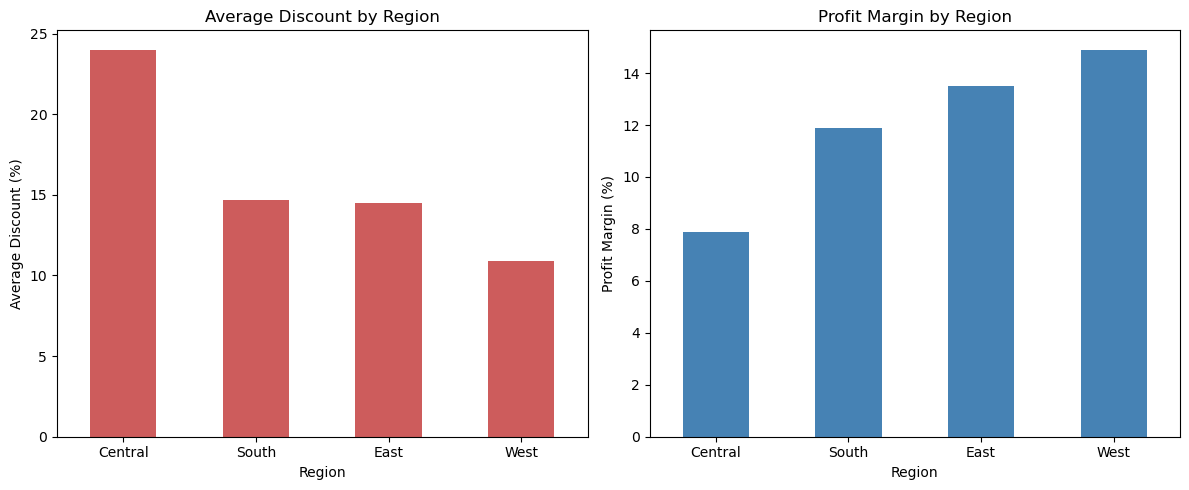

In [56]:
region_check = pd.DataFrame({
    'Avg Discount %': df.groupby('Region')['Discount'].mean() * 100,
    'Margin %': region_profit['Margin %']
}).round(1).sort_values('Margin %')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

region_check['Avg Discount %'].plot(kind='bar', ax=axes[0], color='indianred')
axes[0].set_title('Average Discount by Region')
axes[0].set_xlabel('Region')
axes[0].set_ylabel('Average Discount (%)')
axes[0].tick_params(axis='x', rotation=0)

region_check['Margin %'].plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('Profit Margin by Region')
axes[1].set_xlabel('Region')
axes[1].set_ylabel('Profit Margin (%)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Observation: Discounting and Regional Profit

Central has the highest average discount (about 24%, compared with about 11% in the West) and the highest share of loss-making product lines (about 32%, compared with about 10% in the West). This suggests that heavy discounting is linked to Central's weak margin.

Discounting does not explain everything, though. East and South have almost the same average discount (about 14.5%), but East has more loss-making product lines than South and a higher margin. Other factors, such as the mix of products sold in each region, probably also play a part.

## Segment Profit

In [57]:
segment_profit = df.groupby('Segment')[['Sales', 'Profit']].sum()
segment_profit['Margin %'] = (segment_profit['Profit'] / segment_profit['Sales'] * 100).round(1)
segment_profit.sort_values('Profit')

,Sales,Profit,Margin %
Segment,,,
Home Office,4.296531e+05,60298.6785,14.0
Corporate,7.061464e+05,91979.1340,13.0
Consumer,1.161401e+06,134119.2092,11.5


### Observation: Profit by Segment

Consumer is the largest segment and contributes the most profit (about 134K), followed by Corporate (about 92K) and Home Office (about 60K). The ranking by profit matches the ranking by sales.

Profit margin shows the opposite order. Home Office keeps the largest share of its sales as profit (14.0%), followed by Corporate (13.0%) and Consumer (11.5%). Consumer earns the most in total because it is the largest segment, not because it keeps more of each sale. The margin differences between segments are small, so the segments perform fairly similarly.

## Discount Level vs Profit

In [58]:
discount_profit = df.groupby('Discount')['Profit'].agg(['mean', 'sum', 'count']).round(2)
discount_profit

,mean,sum,count
Discount,,,
0.00,66.90,320987.60,4798
0.10,96.06,9029.18,94
0.15,27.29,1418.99,52
0.20,24.70,90337.31,3657
0.30,-45.68,-10369.28,227
0.32,-88.56,-2391.14,27
0.40,-111.93,-23057.05,206
0.45,-226.65,-2493.11,11
0.50,-310.70,-20506.43,66


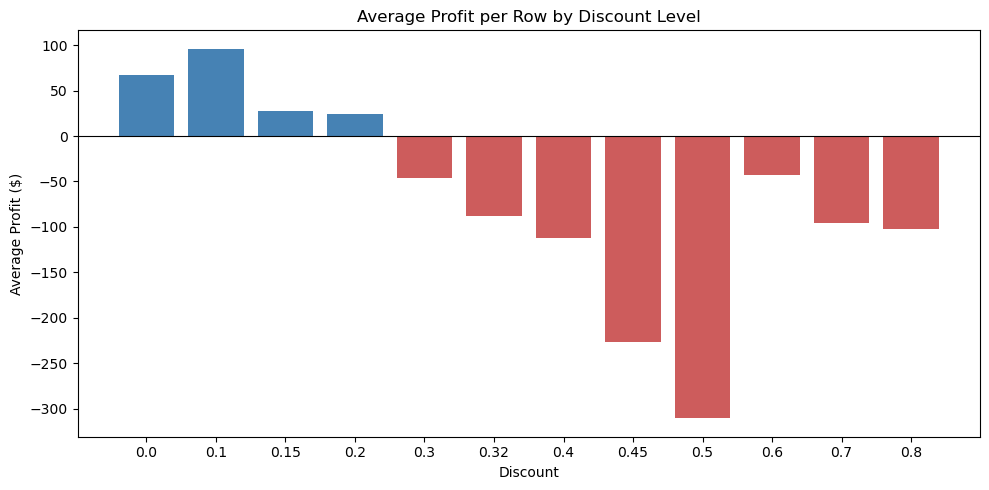

In [59]:
colors = ['indianred' if m < 0 else 'steelblue' for m in discount_profit['mean']]

plt.figure(figsize=(10, 5))
plt.bar(discount_profit.index.astype(str), discount_profit['mean'], color=colors)
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Average Profit per Row by Discount Level')
plt.xlabel('Discount')
plt.ylabel('Average Profit ($)')
plt.tight_layout()
plt.show()

### Observation: Discount Level and Profit

Profit holds up at low discounts and collapses at high ones. At discount levels up to 20%, the average profit per product line is positive. From 30% upward, it is negative at every level. About 86% of the product lines have a discount of 20% or less, and they generate almost all of the profit (about 422K in total). The remaining 1,393 product lines (about 14%) have discounts above 20% and lose about 135K in total. Discounts of 70% and 80% are not rare (418 and 300 rows), and together they account for about 70K of the losses.

This explains why the correlation between Discount and Profit was weak (about -0.22): profit does not decline gradually, it holds until about 20% and then turns negative. A few levels have very few rows (such as 45%), so single levels should not be over-read, but the difference between the groups is clear.

This is an association, not proof of cause: heavily discounted items may also be products that were already low-margin, which I'll check next.

In [60]:
#do the loss-making sub-categories get the heaviest discounts?
subcat_discount = df.groupby('Sub-Category').agg(
    avg_discount=('Discount', 'mean'),
    total_profit=('Profit', 'sum'),
    share_high_discount=('Discount', lambda s: (s > 0.2).mean())
).round(3).sort_values('total_profit')
subcat_discount

,avg_discount,total_profit,share_high_discount
Sub-Category,,,
Tables,0.261,-17725.481,0.552
Bookcases,0.211,-3472.556,0.307
Supplies,0.077,-1189.100,0.000
Fasteners,0.082,949.518,0.000
Machines,0.306,3384.757,0.461
Labels,0.069,5546.254,0.000
Art,0.075,6527.787,0.000
Envelopes,0.080,6964.177,0.000
Furnishings,0.138,13059.144,0.144


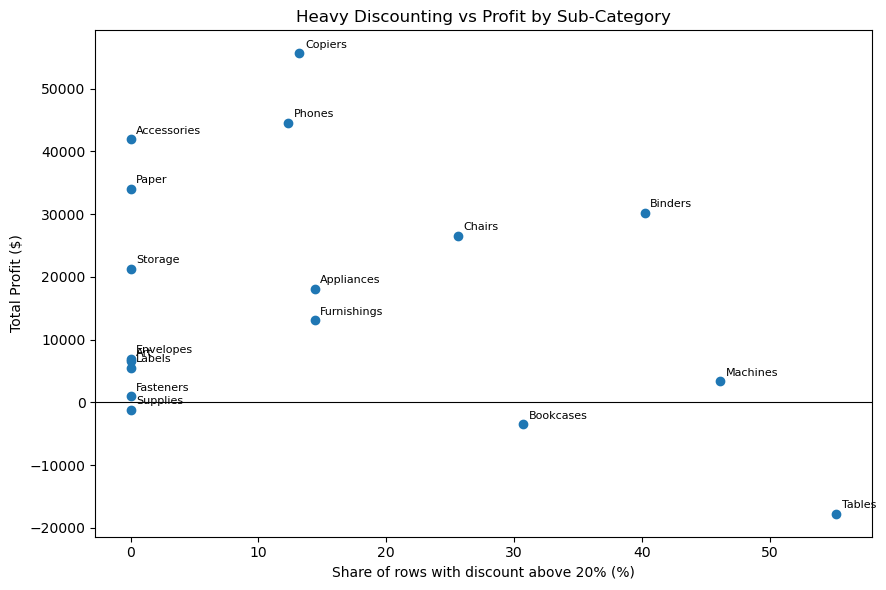

In [61]:
plt.figure(figsize=(9, 6))
plt.scatter(subcat_discount['share_high_discount'] * 100, subcat_discount['total_profit'])
for name, row in subcat_discount.iterrows():
    plt.annotate(name, (row['share_high_discount'] * 100, row['total_profit']),
                 fontsize=8, xytext=(4, 4), textcoords='offset points')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Heavy Discounting vs Profit by Sub-Category')
plt.xlabel('Share of rows with discount above 20% (%)')
plt.ylabel('Total Profit ($)')
plt.tight_layout()
plt.show()

### Observation: Discounting by Sub-Category

The sub-categories with weak profit are also among the most heavily discounted. Tables lose about 17.7K, with an average discount of about 26% and 55% of their product lines discounted by more than 20%. Machines and Bookcases show a similar pattern (46% and 31% of lines above 20%), with near-zero profit for Machines and a loss for Bookcases. In contrast, eight sub-categories have no product lines with discounts above 20%, and seven of them are profitable.

The pattern is not perfect. Binders are heavily discounted (about 40% of lines above 20%) and still earn about 30K, and Supplies lose money despite almost no heavy discounting. So discounting is linked to weak profit in some sub-categories but is not the only cause, but something else is also going on.

## Is It Really the Discounts?

The results so far show that heavily discounted items lose money. But there is another possible explanation: those items may have had low margins to begin with, so they would have lost money even without the discount. The next two checks test this by comparing the same sub-categories and the same products at different discount levels.

##### Check 1: Tables, Bookcases, and Machines

I chose these three sub-categories because they had the weakest profit (Tables lost about 17.7K, Bookcases about 3.5K, and Machines made only about 3.4K on about 189K of sales) and because many of their items were sold with a discount above 20% (55%, 31%, and 46%). I compare their profit margin with no discount, with a discount of up to 20%, and with a discount above 20%.

Supplies also lost money, but I left them out because they have no items sold above a 20% discount, so there is no heavy discounting to test. Because these three were selected for losing money, the result cannot show that every sub-category behaves the same way.

In [62]:
d = df[df['Sub-Category'].isin(['Tables', 'Bookcases', 'Machines'])].copy()
d['Discount band'] = pd.cut(d['Discount'], [-0.01, 0, 0.2, 1],
                            labels=['0%', 'up to 20%', 'above 20%'])
check = d.groupby(['Sub-Category', 'Discount band'], observed=True).agg(
    rows=('Profit', 'count'), sales=('Sales', 'sum'), profit=('Profit', 'sum'))
check['margin %'] = (check['profit'] / check['sales'] * 100).round(1)
check

rows       sales      profit  margin %
Sub-Category Discount band                                        
Bookcases    0%               60  31935.9800   6075.7117      19.0
             up to 20%        98  54400.0175   1549.4937       2.8
             above 20%        70  28543.9988 -11097.7614     -38.9
Machines     0%               29  71034.0000  27137.8223      38.2
             up to 20%        33  41365.5230   5802.2867      14.0
             above 20%        53  76839.1080 -29555.3521     -38.5
Tables       0%               72  71578.7600  13276.2997      18.5
             up to 20%        71  45430.2320   -303.5580      -0.7
             above 20%       176  89956.5400 -30698.2228     -34.1

##### Observation: Tables, Bookcases, and Machines

All three make a profit when sold without a discount (margins of about 19%, 38%, and 18%). Above a 20% discount, all three lose more than a third of their sales value. This suggests the losses come mainly from heavy discounts and not from the normal prices. Tables are the weakest: even a discount of up to 20% brings them to about break-even. This comparison groups different items together, so it shows a link and does not prove the discount is the only cause.

##### Check 2: All Products Sold at Both Low and High Discounts

Since the three sub-categories above were chosen for losing money, I repeat the test without any selection. I keep only the products that were sold both at a discount of up to 20% and at a discount above 20%, and compare the average profit per item sold in each group. This way, the same products appear in both groups.

In [63]:
d2 = df.copy()
d2['Band'] = d2['Discount'].apply(lambda x: 'up to 20%' if x <= 0.2 else 'above 20%')
both = d2.groupby('Product Name')['Band'].nunique()
both = both[both == 2].index
d2[d2['Product Name'].isin(both)].groupby('Band')['Profit'].agg(['mean', 'count']).round(1)

,mean,count
Band,,
above 20%,-91.6,1333
up to 20%,85.1,2556


##### Observation: Same Products at Low and High Discounts

For products sold at both discount levels, the average profit per item sold is about 85 at a discount of up to 20%, and about -92 above 20%. So the same products make money at low discounts and lose money at high ones, which supports the idea that discounting is likely a major driver of the losses. It is not a controlled test, because the sales also differ by region, date, and customer.

## Is the Last Quarter Also the Most Profitable?
##### The last quarter has the highest sales every year. Before recommending a focus on it, I'll check whether it also has the highest profit, and whether it depends on heavier discounts.

In [64]:
quarter_check = df.groupby('Quarter').agg(
    sales=('Sales', 'sum'),
    profit=('Profit', 'sum'),
    avg_discount=('Discount', 'mean')
).round(2)
quarter_check['margin %'] = (quarter_check['profit'] / quarter_check['sales'] * 100).round(1)
quarter_check

,sales,profit,avg_discount,margin %
Quarter,,,,
1,359681.58,48023.74,0.15,13.4
2,445509.62,55284.54,0.16,12.4
3,613932.11,72467.08,0.15,11.8
4,878077.56,110621.66,0.16,12.6


##### observation:  Quarterly Profit
The last quarter is the strongest for profit as well as sales. It brings in about 38% of sales and about 39% of profit. Its profit margin (12.6%) is about the same as the whole-year margin (about 12.5%), and the average discount is almost the same in every quarter (15% to 16%). So the strong last quarter is not the result of heavier discounting, and focusing on it makes sense.

## Conclusion and Recommendations

**In short:** the store's biggest problem is heavy discounting. Items sold with a discount above 20% lost about 135K, which is almost half of the 286K total profit. The weakest areas are Tables, Bookcases, Machines, and the Central region. The first step is to test a 20% maximum discount on those areas.

**What I found**

Making a lot of sales does not mean making a lot of profit. Furniture sells about as much as the other two categories but keeps only 2.5% of it as profit. The Central region keeps about half as much of its sales as the West. Some of the best-selling products lose money. Big discounts are likely a main reason, but not the only one.

Consumers are the biggest customer group and bring the most profit, but the three customer groups perform fairly similarly, so no change is needed there. Sales grew about 51% from 2014 to 2017, and the last three months of the year are the strongest every year.

**Recommendations (in order of priority)**

**1. Set a 20% maximum discount, and test it first.**
Items sold with a discount of 20% or less make money on average. From 30% and up, they lose money on average. The 1,393 items sold above 20% lost about 135K in total, while the other 8,601 made about 422K. The same products earn about 85 per item sold at a discount of up to 20% and lose about 92 per item above 20%, so the difference is not only because of which products get heavy discounts. The real gain from a limit is hard to predict, because some customers may buy less if the discounts are lower. I suggest a trial: apply the limit to Tables and Machines for about three months, then compare profit and the number of items sold with the same months of the previous year.

**2. Fix Tables, Bookcases, and Machines.**
Tables lost about 17.7K, and 55% of the Tables items sold had a discount above 20%. Bookcases lost about 3.5K, with 31% above 20%. Machines sold about 189K but made only about 3.4K in profit, with 46% above 20%. All three make a profit when sold without a discount (margins between about 18% and 38%) and lose more than a third of their sales value above a 20% discount, so the losses come mainly from the discounts. Lower the discounts on these three. Tables may need a stricter limit than 20%: Tables sold at 20% off make almost no profit (a margin of about -0.7%), so a 20% limit would stop the big losses but would not make Tables profitable.

**3. Look closely at the Central region.**
Central keeps only 7.9% of its sales as profit, while the West keeps 14.9%. Central also gives the biggest discounts (about 24% on average, against about 11% in the West), and about 1 in 3 of its items sold loses money. The person responsible for Central should review which products get the biggest discounts and who approves them.

**4. Check the costs and prices of Supplies.**
Supplies lose about 1.2K even though they rarely get big discounts, so discounts are not the reason here. The finance or purchasing team should check what these products cost and what they are sold for. It is a small loss, so it is less urgent.

**5. Protect the products that make the most profit.**
Copiers made about 55.6K and keep 37% of their sales as profit. All 13 copier products make a profit. Phones, Accessories, and Paper also do well. One product, the Canon imageCLASS 2200 copier, made about 25.2K, which is about 9% of all profit and almost half of what all copiers earn. It did this with only 5 sales, so the store depends on a few big orders. Avoid heavy discounts on these products and keep them in stock.

**6. Plan for the last three months of the year.**
The fourth quarter brings in about 38% of each year's sales and about 39% of the profit, and its profit margin (12.6%) is about the same as the rest of the year. Stock and staff planning should focus on it.

**Limits of this analysis**

- The data has no cost or stock information, so I can see where profit is lost but not always why. For example, discounts explain the losses in Tables and Machines, but not in Supplies.
- The results show links, not proof, so the ideas above should be tested on a small scale first.
- The data has no age or gender, so customers were looked at by segment only.